# Vẽ ranh giới quyết định của hồi quy Logistic (mục 4.1.3)

Ranh giới $\mathbf{x}^T\mathbf{w} = 0$ là một siêu phẳng: (a) với 1 đặc trưng là một điểm trên trục số, (b) với 2 đặc trưng là một đường thẳng, (c) với 3 đặc trưng là một mặt phẳng.

In [1]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression

IMAGES = Path('.')   # thư mục images/ (notebook chạy trong images/)
np.random.seed(0)

Sinh ba bộ dữ liệu có 1, 2 và 3 đặc trưng, mỗi bộ gồm hai lớp 30 điểm theo phân phối chuẩn. Huấn luyện hồi quy Logistic trên từng bộ để lấy trọng số $\mathbf{w} = (w_0, w_1, \dots, w_d)$.

In [2]:
N = 30   # số điểm mỗi lớp

def make_data(center_0, center_1):
    """Sinh hai lớp điểm quanh hai tâm, trả về X và nhãn y."""
    X0 = np.random.randn(N, len(center_0)) * 0.8 + center_0   # lớp 0
    X1 = np.random.randn(N, len(center_1)) * 0.8 + center_1   # lớp 1
    return np.vstack([X0, X1]), np.array([0] * N + [1] * N)

X2, y2 = make_data([-1, -1], [1.5, 1.5])               # 2 đặc trưng
X3, y3 = make_data([-1, -1, -1], [1.5, 1.5, 1.5])      # 3 đặc trưng
X1, y1 = make_data([-1.5], [1.5])                      # 1 đặc trưng

model_1d = LogisticRegression().fit(X1, y1)
model_2d = LogisticRegression().fit(X2, y2)
model_3d = LogisticRegression().fit(X3, y3)
w_1d = np.r_[model_1d.intercept_, model_1d.coef_[0]]   # (w0, w1)
w_2d = np.r_[model_2d.intercept_, model_2d.coef_[0]]   # (w0, w1, w2)
w_3d = np.r_[model_3d.intercept_, model_3d.coef_[0]]   # (w0, w1, w2, w3)
print('w (1 đặc trưng):', w_1d.round(3))
print('w (2 đặc trưng):', w_2d.round(3))
print('w (3 đặc trưng):', w_3d.round(3))

w (1 đặc trưng): [0.498 2.282]
w (2 đặc trưng): [-1.337  1.67   1.588]
w (3 đặc trưng): [-0.891  1.077  1.279  1.291]


Vẽ hình và lưu ảnh. Ranh giới $\mathbf{x}^T\mathbf{w} = 0$ trong từng trường hợp:

- 1 đặc trưng: $w_0 + w_1 x_1 = 0$ là điểm $x_1 = -w_0/w_1$.
- 2 đặc trưng: $w_0 + w_1 x_1 + w_2 x_2 = 0$ là đường thẳng $x_2 = -(w_0 + w_1 x_1)/w_2$.
- 3 đặc trưng: $w_0 + w_1 x_1 + w_2 x_2 + w_3 x_3 = 0$ là mặt phẳng $x_3 = -(w_0 + w_1 x_1 + w_2 x_2)/w_3$.

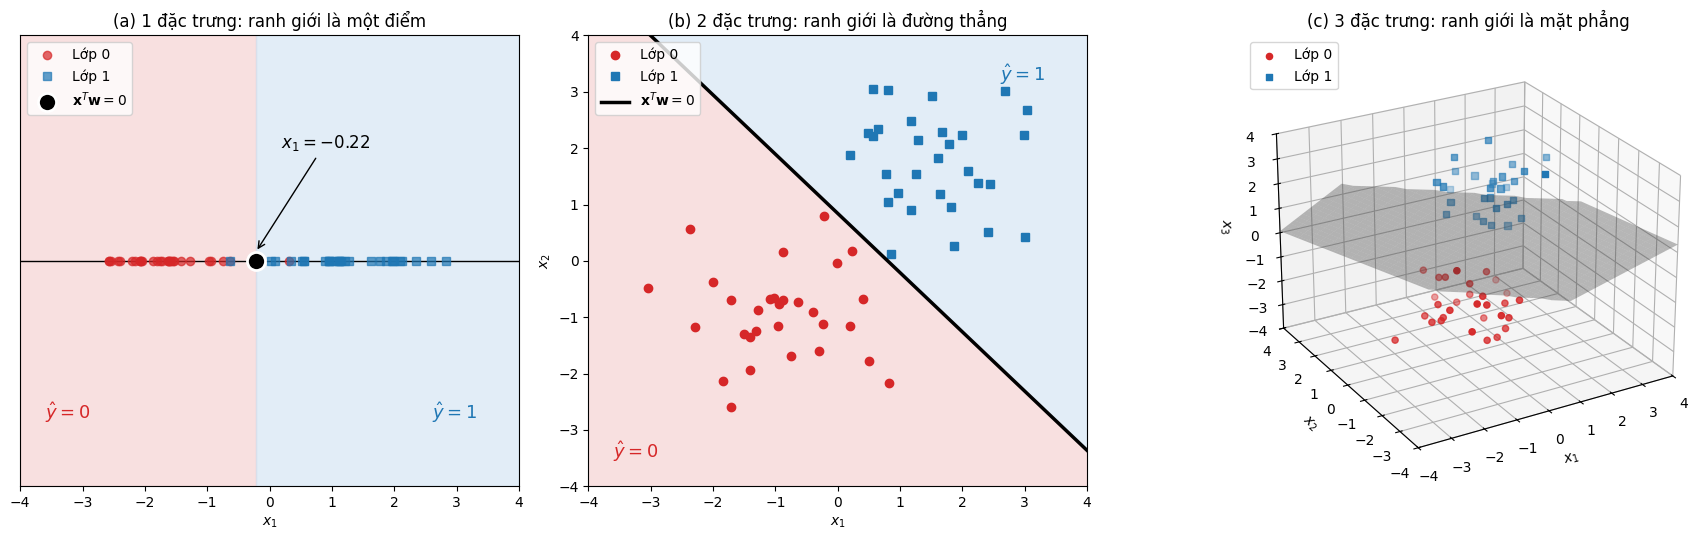

In [3]:
fig = plt.figure(figsize=(18, 5.5))
grid_spec = fig.add_gridspec(1, 3, width_ratios=[1, 1, 1.25])   # cột hình 3 chiều rộng hơn

# (a) 1 đặc trưng: ranh giới là một điểm chia trục số thành hai nửa
ax = fig.add_subplot(grid_spec[0])
point = -w_1d[0] / w_1d[1]          # điểm ranh giới x1 = -w0 / w1
ax.axvspan(-4, point, color='#F4CCCC', alpha=0.6)
ax.axvspan(point, 4, color='#CFE2F3', alpha=0.6)
ax.axhline(0, color='black', lw=1)
ax.plot(X1[y1 == 0, 0], np.zeros(N), 'o', color='#D62728', alpha=0.7, label='Lớp 0')
ax.plot(X1[y1 == 1, 0], np.zeros(N), 's', color='#1F77B4', alpha=0.7, label='Lớp 1')
ax.plot(point, 0, 'o', color='black', ms=13, mec='white', mew=2, zorder=5,
        label=r'$\mathbf{x}^T\mathbf{w} = 0$')
ax.annotate(f'$x_1 = {point:.2f}$', (point, 0.04), (point + 0.4, 0.5), fontsize=12,
            arrowprops=dict(arrowstyle='->'))
ax.text(-3.6, -0.7, r'$\hat{y} = 0$', fontsize=13, color='#D62728')
ax.text(2.6, -0.7, r'$\hat{y} = 1$', fontsize=13, color='#1F77B4')
ax.set_xlim(-4, 4); ax.set_ylim(-1, 1)
ax.set_yticks([])
ax.set_xlabel('$x_1$')
ax.set_title('(a) 1 đặc trưng: ranh giới là một điểm')
ax.legend(loc='upper left')

# (b) 2 đặc trưng: tô màu hai nửa mặt phẳng và vẽ đường thẳng ranh giới
ax = fig.add_subplot(grid_spec[1])
grid = np.linspace(-4, 4, 200)   # lưới để tô màu hai vùng
g1, g2 = np.meshgrid(grid, grid)
score = w_2d[0] + w_2d[1] * g1 + w_2d[2] * g2   # giá trị x^T w trên lưới
ax.contourf(g1, g2, score >= 0, levels=[-0.5, 0.5, 1.5], colors=['#F4CCCC', '#CFE2F3'], alpha=0.6)
ax.plot(X2[y2 == 0, 0], X2[y2 == 0, 1], 'o', color='#D62728', label='Lớp 0')
ax.plot(X2[y2 == 1, 0], X2[y2 == 1, 1], 's', color='#1F77B4', label='Lớp 1')
ax.plot(grid, -(w_2d[0] + w_2d[1] * grid) / w_2d[2], 'k-', lw=2.5,
        label=r'$\mathbf{x}^T\mathbf{w} = 0$')
ax.text(-3.6, -3.5, r'$\hat{y} = 0$', fontsize=13, color='#D62728')
ax.text(2.6, 3.2, r'$\hat{y} = 1$', fontsize=13, color='#1F77B4')
ax.set_xlim(-4, 4); ax.set_ylim(-4, 4)
ax.set_xlabel('$x_1$'); ax.set_ylabel('$x_2$')
ax.set_title('(b) 2 đặc trưng: ranh giới là đường thẳng')
ax.legend(loc='upper left')

# (c) 3 đặc trưng: vẽ mặt phẳng ranh giới trong không gian 3 chiều
ax = fig.add_subplot(grid_spec[2], projection='3d')
p1, p2 = np.meshgrid(np.linspace(-4, 4, 60), np.linspace(-4, 4, 60))
p3 = -(w_3d[0] + w_3d[1] * p1 + w_3d[2] * p2) / w_3d[3]   # mặt phẳng x^T w = 0
p3[(p3 < -4) | (p3 > 4)] = np.nan                         # chỉ vẽ phần nằm trong khung hình
ax.plot_surface(p1, p2, p3, color='gray', alpha=0.35)
ax.scatter(*X3[y3 == 0].T, marker='o', color='#D62728', label='Lớp 0')
ax.scatter(*X3[y3 == 1].T, marker='s', color='#1F77B4', label='Lớp 1')
ax.set_xlim(-4, 4); ax.set_ylim(-4, 4); ax.set_zlim(-4, 4)
ax.set_xlabel('$x_1$'); ax.set_ylabel('$x_2$'); ax.set_zlabel('$x_3$')
ax.view_init(elev=25, azim=-120)
ax.set_title('(c) 3 đặc trưng: ranh giới là mặt phẳng')
ax.legend(loc='upper left')

fig.tight_layout()
fig.savefig(IMAGES / 'hyperplane.png', dpi=150)